## MTL Trajet: 14 Cycling Directness, Destination, and Temperature (Flag 14)

### Dataset Overview

Multi-user cycling trajectories with route directness, temperature, destination land use, time period, and timestamped GPS points; destination clusters are map-matched to Technopôle Angus, Mile End / Boulevard Saint-Laurent, and Parc du Canal-de-Lachine, and point records include a Boolean if_bike field for bike-lane presence.

The primary table is loaded into `df`; the supporting GPS table is loaded into `user_df`.

Goal: Find obvious cycling patterns in the city and exceptional cases if possible based on trajectories of different users.

Role: Urban cycling-pattern analyst


Category: Multi-user cycling route directness, partial bike-lane use, time-period destinations, and temperature-speed patterns

`route_directness_ratio` is path length divided by the straight-line origin-to-destination distance. `if_bike` is a Boolean point-level indicator that the GPS point lies on a bike-lane segment.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import numpy as np
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
points=pd.read_csv('trajectory_points.csv')


## Load Dataset

The primary table is loaded into `df`; the supporting trajectory table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How many cycling trajectories lie below versus above a route-directness ratio of 1.5?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

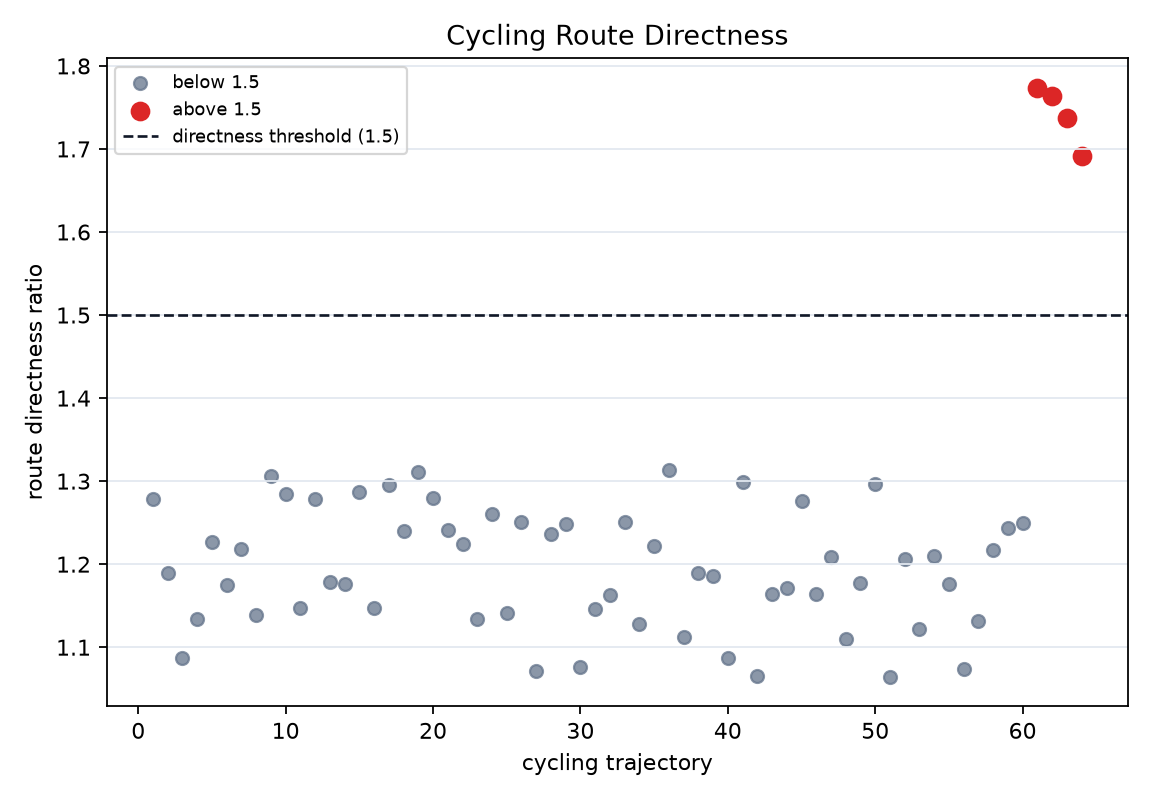

In [ ]:
df.assign(directness_band=np.where(df.route_directness_ratio.lt(1.5), 'below 1.5', 'above 1.5')).groupby('directness_band').size()
from IPython.display import Image, display
display(Image(filename='visualizations/cycling_directness_distribution.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "cycling_route_directness",
  "insight": "Cycling trajectories usually follow a route directness ratio lower than 1.5.",
  "insight_type": "overall_pattern",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Cycling Route Directness",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/cycling_directness_distribution.png"
  },
  "question": "How many cycling trajectories lie below versus above a route-directness ratio of 1.5?",
  "code": "df.assign(directness_band=np.where(df.route_directness_ratio.lt(1.5), 'below 1.5', 'above 1.5')).groupby('directness_band').size()",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "transport_mode",
    "gps_position",
    "trajectory_id"
  ]
}

### **Question 2**: For the cycling trajectories above the directness threshold, how are bike-lane points distributed along the route?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

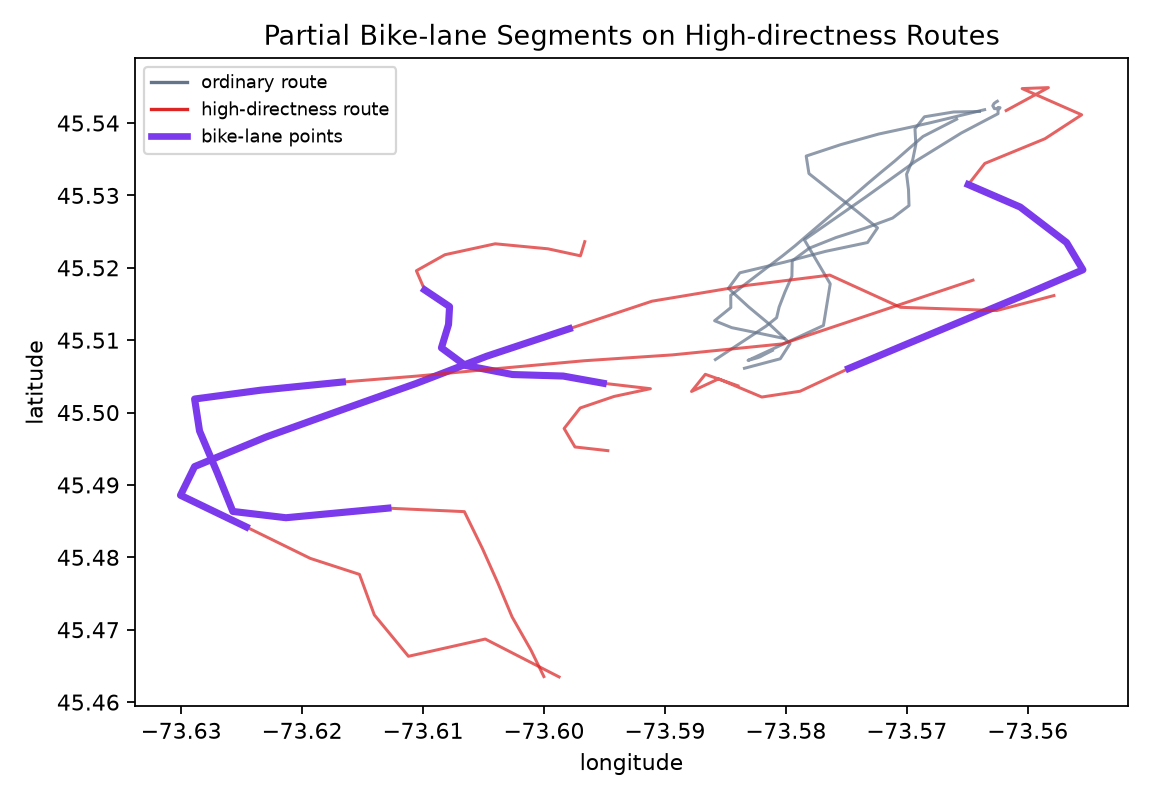

In [ ]:
points.groupby('trajectory_id').if_bike.sum().to_frame('bike_lane_point_count').join(df.set_index('trajectory_id').route_directness_ratio)
from IPython.display import Image, display
display(Image(filename='visualizations/partial_bike_lane_routes.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "cycling_bike_lane_exception",
  "insight": "The four cycling trajectories with a route directness ratio above 1.5 all contain bike-lane points along only part of the route.",
  "insight_type": "exception_deviation",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "High-directness Cycling Routes and Bike-lane Points",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/partial_bike_lane_routes.png"
  },
  "question": "For the cycling trajectories above the directness threshold, how are bike-lane points distributed along the route?",
  "code": "points.groupby('trajectory_id').if_bike.sum().to_frame('bike_lane_point_count').join(df.set_index('trajectory_id').route_directness_ratio)",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "transport_mode",
    "gps_position",
    "bike_lane_presence",
    "trajectory_id"
  ]
}

### **Question 3**: How do the endpoint clusters and official mapped land uses differ across morning, midday, and evening cycling trips?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

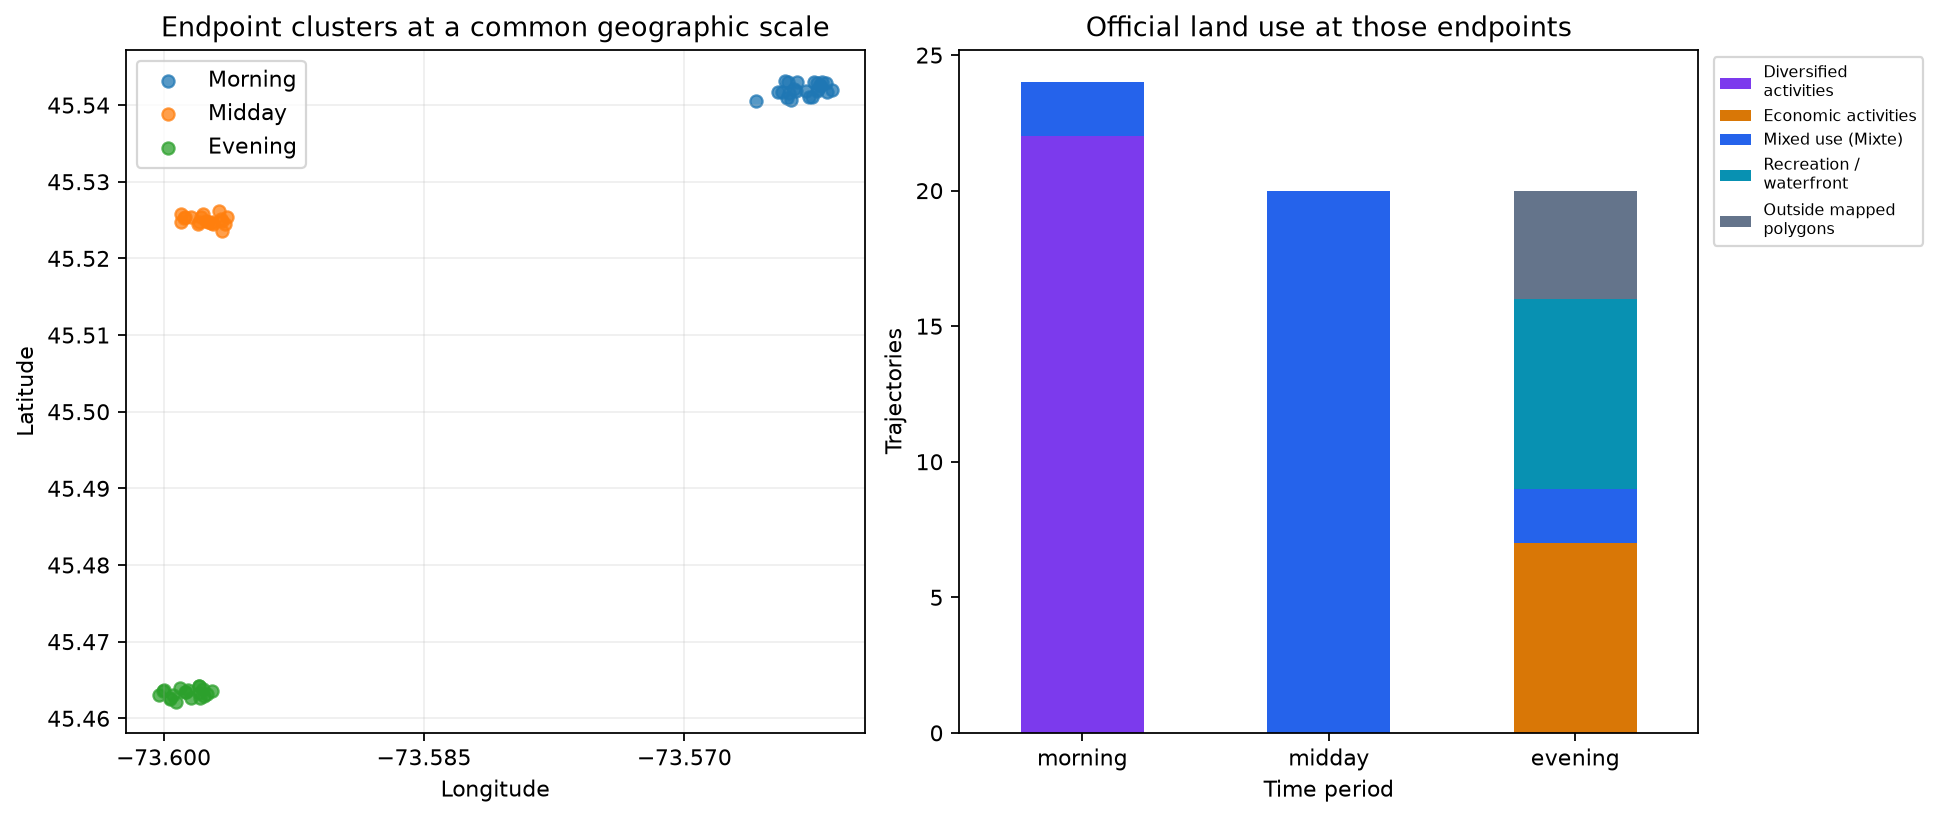

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
df = pd.read_csv(dataset_path)
points = pd.read_csv(Path(dataset_path).with_name('trajectory_points.csv'))
print(pd.crosstab(df.time_period,df.destination_land_use)); print(df.groupby('time_period')[['end_lon','end_lat']].agg(['mean','std']))

from IPython.display import Image, display
display(Image(filename='visualizations/cycling_destinations_by_time_period.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "cycling_destination_time_period",
  "insight": "Cycling destinations form distinct morning, midday, and evening spatial clusters. Morning endpoints are mainly in diversified-activity areas and midday endpoints are in Mixte areas; evening endpoints span several mapped land uses, with four outside the reference polygons.",
  "evidence": "Morning: 22 Activités diversifiées and 2 Mixte; midday: 20 Mixte; evening: 7 recreation/waterfront, 7 economic activities, 2 Mixte and 4 Unmapped.",
  "insight_type": "group_comparison",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Cycling Destinations by Time Period",
    "description": "Recomputed from the delivered fixed GPS coordinates and the archived official PUM2050 Affectatio polygons; Unmapped denotes no containing polygon.",
    "file": "visualizations/cycling_destinations_by_time_period.png"
  },
  "question": "How do the endpoint clusters and official mapped land uses differ across morning, midday, and evening cycling trips?",
  "code": "import pandas as pd\nimport numpy as np\nfrom pathlib import Path\ndf = pd.read_csv(dataset_path)\npoints = pd.read_csv(Path(dataset_path).with_name('trajectory_points.csv'))\nprint(pd.crosstab(df.time_period,df.destination_land_use)); print(df.groupby('time_period')[['end_lon','end_lat']].agg(['mean','std']))\n",
  "insight_value": {
    "Activités diversifiées": {
      "evening": 0,
      "midday": 0,
      "morning": 22
    },
    "Activités économiques": {
      "evening": 7,
      "midday": 0,
      "morning": 0
    },
    "Mixte": {
      "evening": 2,
      "midday": 20,
      "morning": 2
    },
    "Récréation et accès aux rives": {
      "evening": 7,
      "midday": 0,
      "morning": 0
    },
    "Unmapped": {
      "evening": 4,
      "midday": 0,
      "morning": 0
    }
  },
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "transport_mode",
    "trajectory_timestamp",
    "trajectory_id",
    "gps_position",
    "land_use_reference"
  ]
}

### **Question 4**: How does average cycling speed vary with temperature?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

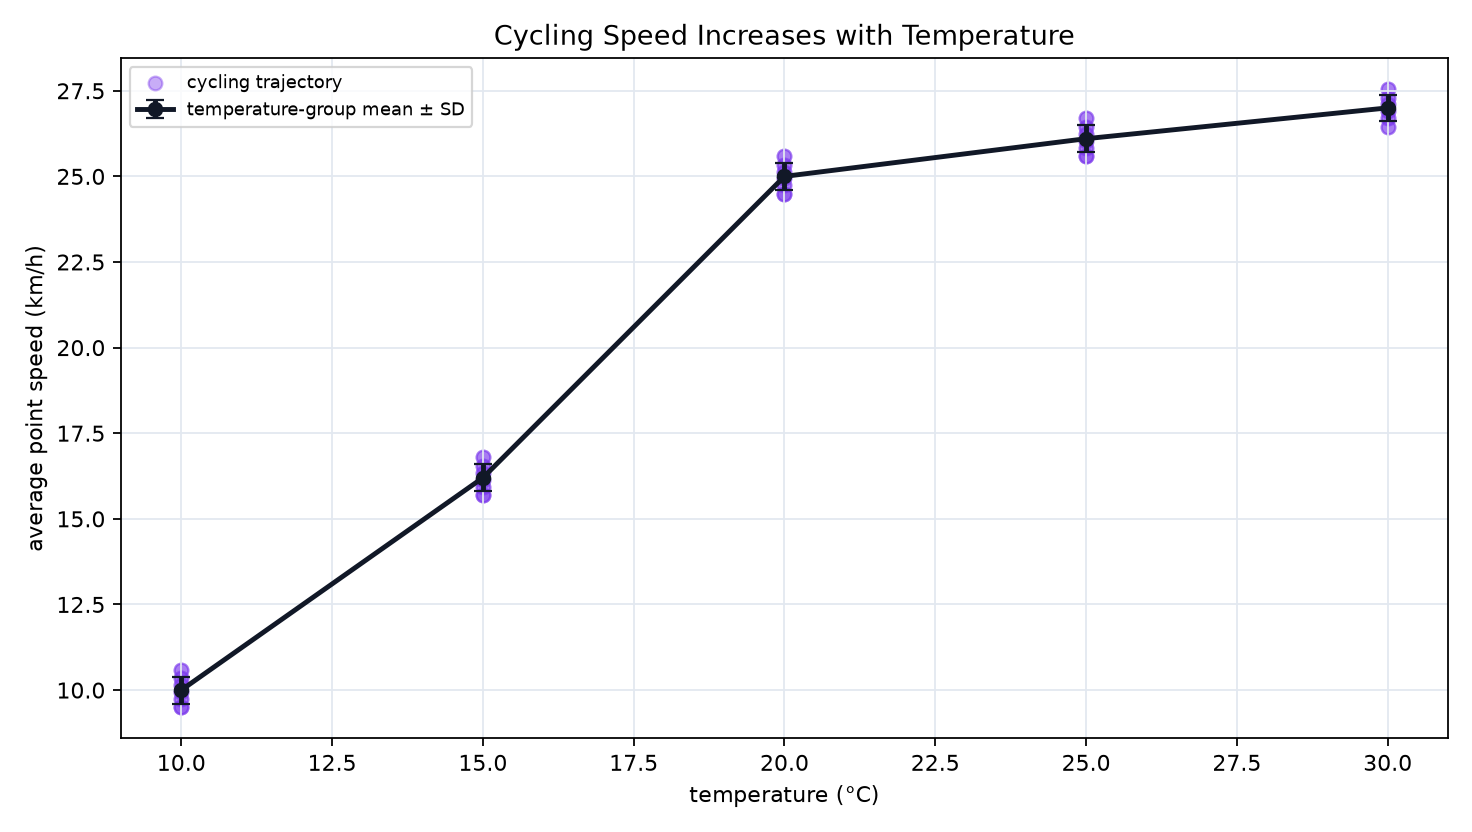

In [ ]:
df.groupby('temperature_c').avg_point_speed_kmh.agg(['count','mean','std'])
from IPython.display import Image, display
display(Image(filename='visualizations/cycling_speed_by_temperature.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "cycling_temperature_speed",
  "insight": "Cycling speed generally increases with temperature.",
  "evidence": "Average cycling speed increases with temperature, from 10 km/h at 10°C to 25 km/h at 20°C and 27 km/h at 30°C.",
  "insight_type": "factor_relationship",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Cycling Speed by Temperature",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/cycling_speed_by_temperature.png"
  },
  "question": "How does average cycling speed vary with temperature?",
  "code": "df.groupby('temperature_c').avg_point_speed_kmh.agg(['count','mean','std'])",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "transport_mode",
    "temperature",
    "point_speed",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 14)

Cycling trajectories usually follow a route directness ratio lower than 1.5. The four cycling trajectories with a route directness ratio above 1.5 all contain bike-lane points along only part of the route. Cycling destinations form distinct morning, midday, and evening spatial clusters. Morning endpoints are mainly in diversified-activity areas and midday endpoints are in Mixte areas; evening endpoints span several mapped land uses, with four outside the reference polygons. Cycling speed generally increases with temperature.
